#### Regression Tasks
Predict the Demand of a session before it starts.

#### Step-0: Imports

In [55]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import shap
from lime.lime_tabular import LimeTabularExplainer

#### Step-1: Load data and split by time 

In [3]:
# Loading the data
df= pd.read_csv("../data/cleaned/model_ready.csv", parse_dates=['StartDatetime'])

# Splitting the data
split= int(len(df)*0.8)
train= df.iloc[:split]
test= df.iloc[split:]

print(train.shape, test.shape)
print('Train Ends: ',train['StartDatetime'].max())
print('Test Start: ',test['StartDatetime'].min(),'Test Ends: ',test['StartDatetime'].max())

(57670, 14) (14418, 14)
Train Ends:  2022-07-30 21:59:00
Test Start:  2022-07-30 22:02:00 Test Ends:  2022-09-30 23:11:00


#### Step 2: Features (X) and target (y)

In [4]:
num_cols= ['ChargerCompany', 'ChargerType', 'Hour', 'Weekday', 'IsWeekend', 'IsGuest', 'UserPastSessions', 
           'UserPastAvgDemand', 'ChargerPastSessions', 'ChargerPastAvgDemand']
cat_cols= ['Location']

# Dividing columns to features and target
X_train= train[num_cols + cat_cols]
y_train= train['Demand']
X_test= test[num_cols + cat_cols]
y_test= test['Demand']

#### Step-3: Preprocessing

In [5]:
# Creating a numerical pipeline to mention which processing steps to be present
num_pipe= Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
# Creating a pipeline for both numerical and categorical columns
preprocess= ColumnTransformer([('num', num_pipe, num_cols),('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)])

#### Step-4: Compare models with time based cross validation

In [30]:
# Splitting into time series split for the cross validation
tscv= TimeSeriesSplit(n_splits=3)

# Function to take the model and train and test based on cross validation
def cv_score(name, model):
    pipe= Pipeline([('preprocess', preprocess), ('model', model)])
    scores= cross_validate(pipe, X_train, y_train, cv=tscv,
                           scoring=['neg_mean_absolute_error', 'neg_mean_squared_error', 'neg_root_mean_squared_error', 'r2'],
                           return_train_score=True)
    print(name,
          '| Train MAE:', round(-scores['train_neg_mean_absolute_error'].mean(), 2),
          '| Val MAE:', round(-scores['test_neg_mean_absolute_error'].mean(), 2),
          '| Val MSE:', round(-scores['test_neg_mean_squared_error'].mean(), 2),
          '| Val RMSE:', round(-scores['test_neg_root_mean_squared_error'].mean(), 2),
          '| Train R2:', round(scores['train_r2'].mean(), 3),
          '| Val R2:', round(scores['test_r2'].mean(), 3))

In [31]:
# Baseline: always predicts the train median (minimum bar to beat)
cv_score('Baseline (median)', DummyRegressor(strategy='median'))

Baseline (median) | Train MAE: 9.79 | Val MAE: 10.15 | Val MSE: 191.85 | Val RMSE: 13.85 | Train R2: -0.046 | Val R2: -0.053


In [32]:
# Linear Regression: straight-line relationship between features and Demand
cv_score('Linear Regression', LinearRegression())

Linear Regression | Train MAE: 8.07 | Val MAE: 8.21 | Val MSE: 123.7 | Val RMSE: 11.12 | Train R2: 0.296 | Val R2: 0.321


In [33]:
# Decision Tree: yes/no splits on features (max_depth limits overfitting)
cv_score('Decision Tree', DecisionTreeRegressor(max_depth=8, random_state=42))

Decision Tree | Train MAE: 7.35 | Val MAE: 8.21 | Val MSE: 130.96 | Val RMSE: 11.44 | Train R2: 0.396 | Val R2: 0.281


In [34]:
# Random Forest: average of many trees built on random samples
cv_score('Random Forest', RandomForestRegressor(n_estimators=100, max_depth=12, n_jobs=-1, random_state=42))

Random Forest | Train MAE: 6.3 | Val MAE: 7.88 | Val MSE: 117.74 | Val RMSE: 10.85 | Train R2: 0.561 | Val R2: 0.354


In [35]:
# Gradient Boosting: trees built one after another, each fixing previous errors
cv_score('Gradient Boosting', GradientBoostingRegressor(random_state=42))


Gradient Boosting | Train MAE: 7.49 | Val MAE: 7.81 | Val MSE: 114.93 | Val RMSE: 10.72 | Train R2: 0.375 | Val R2: 0.369


In [36]:
# XGBoost: optimised gradient boosting with regularisation
cv_score('XGBoost', XGBRegressor(random_state=42, n_jobs=-1))

XGBoost | Train MAE: 6.11 | Val MAE: 8.21 | Val MSE: 128.72 | Val RMSE: 11.34 | Train R2: 0.576 | Val R2: 0.293


In [37]:
# LightGBM: fast gradient boosting that grows trees leaf-wise
cv_score('LightGBM', LGBMRegressor(random_state=42, verbose=-1))

LightGBM | Train MAE: 6.99 | Val MAE: 7.69 | Val MSE: 113.53 | Val RMSE: 10.65 | Train R2: 0.45 | Val R2: 0.377


#### Observations:

1. All models beat the baseline.
2. LightGBM performs best, Gradient Boosting 2nd because boosting captures non-linear patterns and interactions well.
3. Linear Regression is weaker.
4. A single Decision Tree is weaker than the ensembles, many trees combined are more stable than one.
5. Duration is excluded because it is known only after the session ends (data leakage).
6. XGBoost and Random Forest show a large train–validation gap means overfitting; Gradient Boosting and LightGBM generalise better.

#### Step-5: Finetuning LightGBM and Gradient Boosting models

In [40]:
# Tuning LightGBM: trying 10 random combinations, then choosing the one with lowest MAE
lgbm_params= {'model__n_estimators': [100, 200, 300, 500],
              'model__learning_rate': [0.01, 0.05, 0.1],
              'model__num_leaves': [15, 31, 63],
              'model__max_depth': [-1, 5, 10],
              'model__min_child_samples': [20, 50, 100]}

lgbm_pipe= Pipeline([('preprocess', preprocess), ('model', LGBMRegressor(random_state=42, verbose=-1))])
lgbm_search= RandomizedSearchCV(lgbm_pipe, lgbm_params, n_iter=10, cv=tscv, scoring='neg_mean_absolute_error', random_state=42)
lgbm_search.fit(X_train, y_train)

print('Best params:', lgbm_search.best_params_)
print('Best CV MAE:', round(-lgbm_search.best_score_, 2))

Best params: {'model__num_leaves': 31, 'model__n_estimators': 200, 'model__min_child_samples': 50, 'model__max_depth': 10, 'model__learning_rate': 0.05}
Best CV MAE: 7.66


In [41]:
# Tuning Gradient Boosting: same approach
gb_params= {'model__n_estimators': [100, 200, 300],
            'model__learning_rate': [0.05, 0.1],
            'model__max_depth': [3, 4, 5],
            'model__min_samples_leaf': [1, 20, 50]}

gb_pipe= Pipeline([('preprocess', preprocess), ('model', GradientBoostingRegressor(random_state=42))])
gb_search= RandomizedSearchCV(gb_pipe, gb_params, n_iter=10, cv=tscv, scoring='neg_mean_absolute_error', random_state=42)
gb_search.fit(X_train, y_train)

print('Best params:', gb_search.best_params_)
print('Best CV MAE:', round(-gb_search.best_score_, 2))

Best params: {'model__n_estimators': 300, 'model__min_samples_leaf': 50, 'model__max_depth': 4, 'model__learning_rate': 0.05}
Best CV MAE: 7.71


#### Step 6: Final evaluation on the test set

In [43]:
# Final model = tuned LightGBM (already retrained on full train by RandomizedSearchCV)
best_model= lgbm_search.best_estimator_
y_pred= best_model.predict(X_test)

mse= mean_squared_error(y_test, y_pred)
print('Test MAE :', round(mean_absolute_error(y_test, y_pred), 2))
print('Test MSE :', round(mse, 2))
print('Test RMSE:', round(np.sqrt(mse), 2))
print('Test R2  :', round(r2_score(y_test, y_pred), 3))

Test MAE : 8.12
Test MSE : 124.51
Test RMSE: 11.16
Test R2  : 0.354


In [44]:
# Baseline on test: always predict the train median
y_base= np.full(len(y_test), y_train.median())
print('Baseline Test MAE:', round(mean_absolute_error(y_test, y_base), 2))

Baseline Test MAE: 10.54


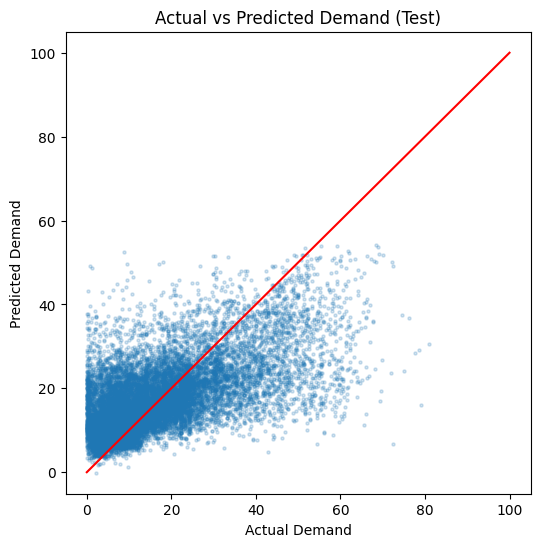

In [49]:
# Actual vs predicted Demand on test data
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.2, s=5)
plt.plot([0, 100], [0, 100], color='red')
plt.xlabel('Actual Demand')
plt.ylabel('Predicted Demand')
plt.title('Actual vs Predicted Demand (Test)')
plt.show()

#### Observations:

1. Test scores are slightly below CV, later months differ a little.
2. Model beats the baseline on unseen data, it generalises.
3. Very large sessions are under-predicted and very small ones over-predicted, Duration (unknown in advance) drives the extremes.

#### Step 7: Feature importance

In [50]:
# Feature names after preprocessing (Location becomes one column per category)
feature_names= best_model.named_steps['preprocess'].get_feature_names_out()

# Gain = how much each feature reduced the error in total across all trees
lgbm_model= best_model.named_steps['model']
gain= lgbm_model.booster_.feature_importance(importance_type='gain')

importance= pd.DataFrame({'Feature': feature_names, 'Importance': gain})
importance['Importance %']= (importance['Importance']/importance['Importance'].sum()*100).round(1)
importance= importance.sort_values('Importance %', ascending=False)
importance.head(10)

,Feature,Importance,Importance %
7,num__UserPastAvgDemand,2.726180e+07,60.6
9,num__ChargerPastAvgDemand,7.195499e+06,16.0
2,num__Hour,5.459508e+06,12.1
6,num__UserPastSessions,1.420295e+06,3.2
8,num__ChargerPastSessions,1.050757e+06,2.3
1,num__ChargerType,6.261432e+05,1.4
0,num__ChargerCompany,3.962609e+05,0.9
14,cat__Location_company,2.065094e+05,0.5
21,cat__Location_resort,1.957606e+05,0.4
17,cat__Location_market,1.859428e+05,0.4


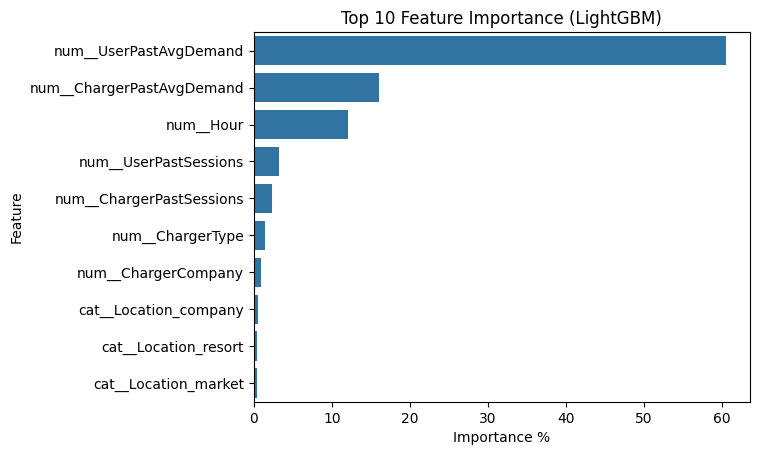

In [51]:
# Top 10 features by importance
sns.barplot(data=importance.head(10), x='Importance %', y='Feature')
plt.title('Top 10 Feature Importance (LightGBM)')
plt.show()

#### Observations: 

1. User's past average demand is the strongest factor means a driver's own history (car and battery size, habits) predicts energy best.
2. Charger's past average and Hour come next means the charger/site and time of day matter.
3. Charger type, company and Location rank lower means much of their effect is already captured by the charger's history.

#### Step-8: SHAP

In [53]:
# Taking 2,000 test rows (SHAP on all rows is slow)
X_sample= X_test.sample(2000, random_state=42)

# Applying  the same preprocessing the model saw, keeping feature names
X_sample_t= best_model.named_steps['preprocess'].transform(X_sample)
X_sample_df= pd.DataFrame(X_sample_t, columns=feature_names)

# TreeExplainer: fast, exact SHAP for tree models like LightGBM
explainer= shap.TreeExplainer(lgbm_model)
shap_values= explainer.shap_values(X_sample_df)

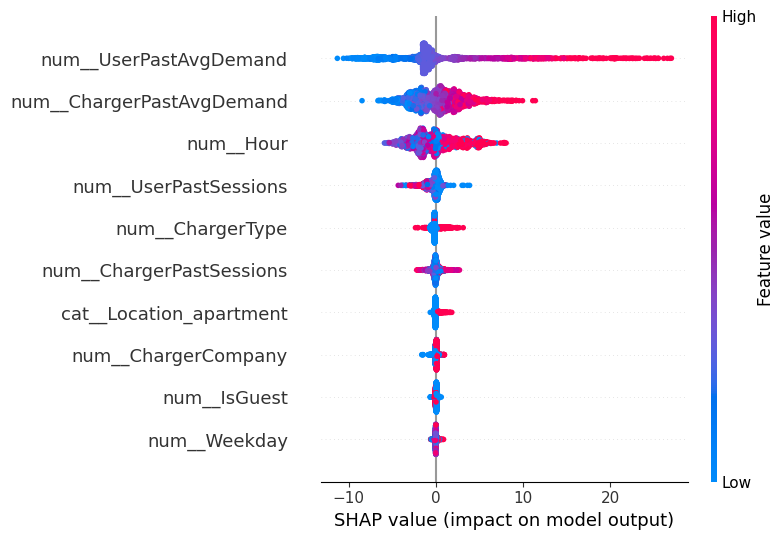

In [54]:
# Each dot = one session; position = effect on prediction, colour = feature value
shap.summary_plot(shap_values, X_sample_df, max_display=10)

#### Observations:

1. UserPastAvgDemand has the widest spread means a user's past average is the main driver; heavy past users get much higher predictions.
2. ChargerPastAvgDemand: high values push predictions up means sites/chargers with high past demand keep getting high demand.
3. SHAP agrees with feature importance means the ranking of factors is consistent.

#### Step 9: LIME
Explaining one sessions prediction

In [56]:
# One example session from the SHAP sample (row 2: frequent user at a public institution)
row_no= 2
print(X_sample.iloc[row_no])
print('Actual Demand:', y_test.loc[X_sample.index[row_no]])
print('Predicted Demand:', round(best_model.predict(X_sample.iloc[[row_no]])[0], 2))

ChargerCompany                           1
ChargerType                              0
Hour                                    11
Weekday                                  4
IsWeekend                                0
IsGuest                                  0
UserPastSessions                        68
UserPastAvgDemand                43.348235
ChargerPastSessions                    375
ChargerPastAvgDemand             24.403867
Location                public institution
Name: 68806, dtype: object
Actual Demand: 64.4
Predicted Demand: 35.77


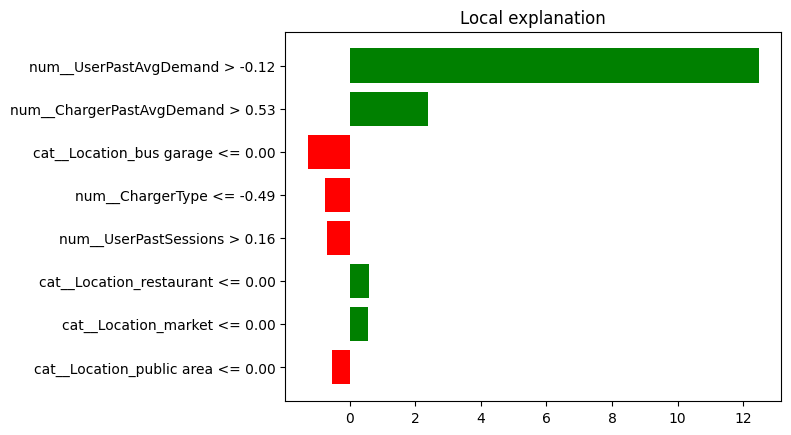

In [57]:
# LIME learns what "normal" values look like from the preprocessed train data
X_train_t= best_model.named_steps['preprocess'].transform(X_train)
lime_explainer= LimeTabularExplainer(X_train_t, feature_names=feature_names, mode='regression', random_state=42)

# Explaining this one session using the LightGBM model
lime_exp= lime_explainer.explain_instance(X_sample_df.iloc[row_no].values, lgbm_model.predict, num_features=8)
lime_exp.as_pyplot_figure()
plt.show()

#### Observations:

1. For this session, the user's high past average is the main reason for the high prediction which means LIME confirms SHAP at the single-session level.
2. The model still predicts well below the actual means even for a heavy user, the exact energy depends on how long they stay.

#### Step 10: Final Observations
Summary – Regression

1. All models beat the baseline (CV MAE 10.15);  features carry real information about Demand.
2. LightGBM performed best in CV (MAE 7.69, R² 0.377); Gradient Boosting was close (MAE 7.81).
3. XGBoost and Random Forest overfit (large train–validation gap); LightGBM and Gradient Boosting generalised better.
4. Tuning gave a small gain (LightGBM CV MAE 7.69 → 7.66); defaults were already reasonable.
5. Final model (tuned LightGBM) on test: MAE 8.12, RMSE 11.16, R² 0.354 vs baseline MAE 10.54.
6. Test error is slightly higher than CV; later months differ a little from training months.
7. Large sessions are under-predicted and small ones over-predicted; without Duration, predictions move towards typical values.
8. Most important factors: user's past average demand, charger's past average demand, and hour (Feature Importance, SHAP and LIME agree).
9. Business: regular users' history is the strongest signal; encourage app login; collecting planned departure time would greatly improve predictions.